# Handwritten Digit Recognition

## Machine Learning Image Classification Project

This project develops a machine learning system for recognizing
handwritten digits from grayscale images.

The project uses the handwritten digits dataset provided by
scikit-learn. Each sample represents one of the digits from 0 to 9
using an 8 × 8 grayscale image.

The project compares a traditional machine learning classification
model with a Multi-Layer Perceptron (MLP) neural network.

## Project Objectives

The main objectives of this project are to:

- Explore and visualize handwritten digit images
- Analyze the distribution of digit classes
- Prepare image data for machine learning
- Establish a Logistic Regression baseline
- Build a neural network using MLPClassifier
- Compare model performance
- Evaluate the final model using multiple metrics
- Analyze the confusion matrix
- Investigate incorrectly classified images
- Test predictions on individual digit images

## Models

The project evaluates:

1. Logistic Regression
2. Multi-Layer Perceptron Neural Network

## Evaluation Metrics

The models are evaluated using:

- Accuracy
- Precision
- Recall
- F1-Score
- Confusion Matrix

## 1. Import Libraries

The project uses NumPy and Pandas for data handling, Matplotlib for
visualization, and scikit-learn for data loading, preprocessing,
model training, hyperparameter tuning, and evaluation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import (
    train_test_split,
    cross_validate,
    GridSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

## 2. Dataset Description

The handwritten digits dataset contains grayscale images of handwritten
digits ranging from 0 to 9.

Each image has a resolution of 8 × 8 pixels. For machine learning,
each image can be represented as a flattened vector containing
64 pixel-value features.

### Dataset Characteristics

- Number of samples: 1,797
- Number of features: 64
- Image resolution: 8 × 8 pixels
- Number of classes: 10
- Target classes: digits 0 through 9

The dataset is included directly in scikit-learn, so no external
dataset download is required.

The original images are stored as 8 × 8 arrays, while the machine
learning feature matrix contains the same images in flattened form.

In [2]:
digits = load_digits()

X = digits.data
y = digits.target

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of classes:", len(np.unique(y)))
print("Classes:", np.unique(y))

X shape: (1797, 64)
y shape: (1797,)
Number of classes: 10
Classes: [0 1 2 3 4 5 6 7 8 9]


## 3. Understanding the Image Representation

The machine learning model receives each image as a flattened vector
containing 64 pixel values.

However, the original image has a two-dimensional structure of
8 × 8 pixels.

Therefore, the same image can be represented in two ways:

- Original representation: 8 × 8 pixels
- Machine learning representation: 64 features

Understanding this transformation is important because the model learns
from the numerical pixel values, while the original two-dimensional
structure allows us to visualize the handwritten digit.

In [3]:
print("Flattened sample shape:", digits.data[0].shape)
print("Original image shape:", digits.images[0].shape)
print("First digit label:", y[0])

Flattened sample shape: (64,)
Original image shape: (8, 8)
First digit label: 0


## 4. Visualizing a Sample Digit

Before training any machine learning model, it is useful to inspect
the actual image represented by the numerical features.

The following visualization displays the first handwritten digit in
the dataset.

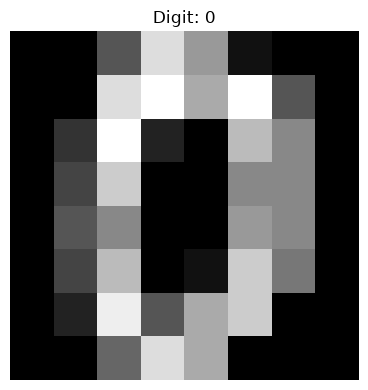

In [4]:
plt.figure(figsize=(4, 4))

plt.imshow(
    digits.images[0],
    cmap="gray"
)

plt.title(f"Digit: {y[0]}")
plt.axis("off")

plt.tight_layout()

plt.savefig(
    "images/sample_digit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5. Visualizing Multiple Digit Examples

A single image does not represent the full variation present in the
dataset.

The following visualization displays several handwritten digit samples
to demonstrate differences in writing style and pixel patterns.

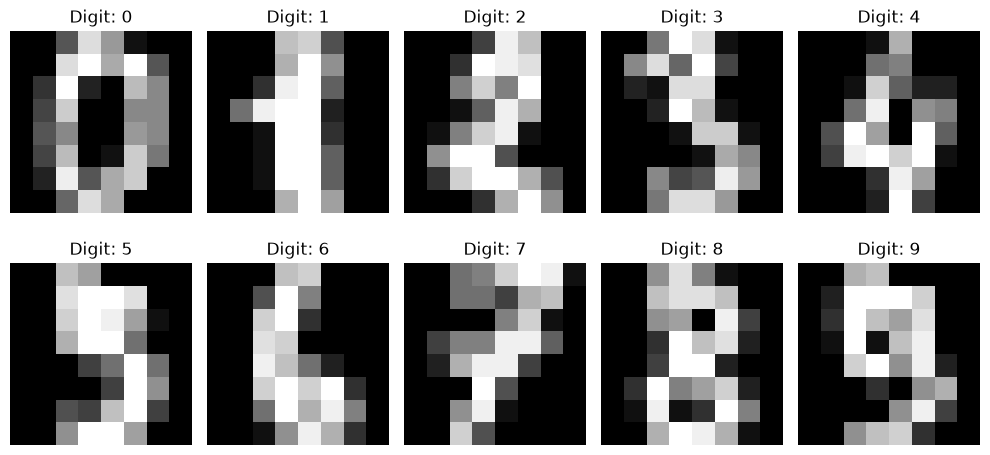

In [5]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(
        digits.images[i],
        cmap="gray"
    )

    plt.title(f"Digit: {y[i]}")
    plt.axis("off")

plt.tight_layout()

plt.savefig(
    "images/sample_digits.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. Exploring the Target Distribution

Before training the models, we examine how many samples are available
for each digit class.

A relatively balanced distribution is desirable because it reduces the
risk of the model being strongly biased toward a particular class.

In [6]:
class_counts = pd.Series(y).value_counts().sort_index()

print(class_counts)

0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64


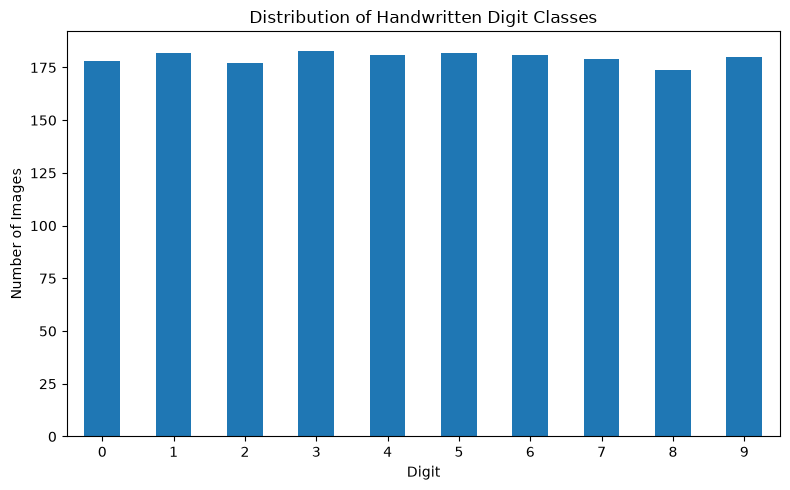

In [7]:
plt.figure(figsize=(8, 5))

class_counts.plot(kind="bar")

plt.title("Distribution of Handwritten Digit Classes")
plt.xlabel("Digit")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "images/digit_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. Data Preparation

Before training the models, the dataset must be divided into training
and testing sets.

The training set will be used to learn patterns from the handwritten
digits, while the testing set will be kept separate for evaluating how
well the models generalize to unseen data.

A stratified split is used so that the proportion of each digit class
remains approximately the same in both the training and testing sets.

The dataset will be divided into:

- 80% training data
- 20% testing data

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1437, 64)
X_test shape: (360, 64)
y_train shape: (1437,)
y_test shape: (360,)


## 8. Examining Pixel Values

Each image is represented using 64 numerical pixel features.

The pixel values describe grayscale intensity. Higher values represent
brighter pixels, while lower values represent darker pixels.

Before preprocessing, we inspect the range of pixel values in the
dataset.

In [9]:
print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())
print("Mean pixel value:", X.mean())

Minimum pixel value: 0.0
Maximum pixel value: 16.0
Mean pixel value: 4.884164579855314


## 9. Feature Scaling

The pixel values in the original dataset range from 0 to 16.

For the neural network, it is useful to standardize the input features
so that they have a similar scale.

Standardization transforms each feature approximately according to:

    z = (x - mean) / standard deviation

This results in features with a mean close to 0 and a standard
deviation close to 1.

The scaler will be fitted only on the training data to avoid data
leakage. The same transformation will then be applied to the testing
data.

For the machine learning models, preprocessing will be handled inside
a scikit-learn Pipeline.

## 10. Baseline Model — Logistic Regression

Logistic Regression is used as the baseline classification model.

Although Logistic Regression is a relatively simple model, it can
perform well on image classification tasks when the classes are
reasonably separable.

The baseline provides a reference point for evaluating whether the
neural network provides improved predictive performance.

In [11]:
logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    (
        "model",
        LogisticRegression(
            max_iter=2000,
            random_state=42
        )
    )
])

logistic_pipeline.fit(X_train, y_train)

logistic_predictions = logistic_pipeline.predict(X_test)

logistic_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)

print("Logistic Regression Accuracy:", logistic_accuracy)

Logistic Regression Accuracy: 0.9722222222222222


### Baseline Evaluation

Accuracy provides the overall proportion of correctly classified
images.

However, because this is a multi-class classification problem, we also
evaluate precision, recall, and F1-score using macro averaging.

Macro averaging calculates the metric independently for each digit
class and then takes the unweighted average across all classes.

In [12]:
logistic_precision = precision_score(
    y_test,
    logistic_predictions,
    average="macro"
)

logistic_recall = recall_score(
    y_test,
    logistic_predictions,
    average="macro"
)

logistic_f1 = f1_score(
    y_test,
    logistic_predictions,
    average="macro"
)

print("Accuracy :", logistic_accuracy)
print("Precision:", logistic_precision)
print("Recall   :", logistic_recall)
print("F1-Score :", logistic_f1)

Accuracy : 0.9722222222222222
Precision: 0.9721260358102464
Recall   : 0.9719047619047618
F1-Score : 0.9719402197048348


In [13]:
print(
    classification_report(
        y_test,
        logistic_predictions
    )
)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.89      0.89      0.89        36
           2       1.00      1.00      1.00        35
           3       0.97      1.00      0.99        37
           4       0.97      1.00      0.99        36
           5       1.00      1.00      1.00        37
           6       1.00      0.97      0.99        36
           7       1.00      1.00      1.00        36
           8       0.89      0.89      0.89        35
           9       1.00      0.97      0.99        36

    accuracy                           0.97       360
   macro avg       0.97      0.97      0.97       360
weighted avg       0.97      0.97      0.97       360



## 11. Cross-Validation of the Baseline Model

The initial evaluation used a single train-test split.

To obtain a more reliable estimate of model performance, 5-fold
cross-validation is performed on the training dataset.

The training data is divided into five folds. The model is trained on
four folds and validated on the remaining fold. This process is
repeated five times so that every fold is used as the validation set.

The mean and standard deviation of the cross-validation scores are
reported to evaluate both average performance and consistency.

In [14]:
cv_results = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision_macro",
        "recall": "recall_macro",
        "f1": "f1_macro"
    },
    return_train_score=False
)

print("Cross-Validation Results")
print("-" * 30)

for metric in ["accuracy", "precision", "recall", "f1"]:
    scores = cv_results[f"test_{metric}"]

    print(
        f"{metric.capitalize():<10}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

Cross-Validation Results
------------------------------
Accuracy  : 0.9701 ± 0.0084
Precision : 0.9712 ± 0.0086
Recall    : 0.9700 ± 0.0085
F1        : 0.9700 ± 0.0087


## 12. Neural Network Model

The next model is a Multi-Layer Perceptron (MLP) neural network.

Unlike the Logistic Regression baseline, the MLP can learn non-linear
relationships between the pixel values and the digit classes.

The network will use:

- 64 input features representing the 64 pixels
- A first hidden layer with 64 neurons
- A second hidden layer with 32 neurons
- ReLU activation functions
- 10 output classes representing digits 0 through 9

The input features will be standardized before being passed to the
neural network.

In [15]:
mlp_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    (
        "model",
        MLPClassifier(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            solver="adam",
            max_iter=300,
            random_state=42
        )
    )
])

### Training the Neural Network

The neural network learns by repeatedly processing the training data
and updating its weights to reduce classification error.

During training, the model goes through multiple iterations of the
learning process.

The training history will later allow us to examine how the loss
changes as training progresses.

In [16]:
mlp_pipeline.fit(X_train, y_train)

mlp_predictions = mlp_pipeline.predict(X_test)

mlp_accuracy = accuracy_score(
    y_test,
    mlp_predictions
)

print("MLP Accuracy:", mlp_accuracy)

MLP Accuracy: 0.9666666666666667


## 13. Neural Network Evaluation

The neural network is evaluated using the same metrics as the baseline
model so that the two approaches can be compared fairly.

The evaluation includes:

- Accuracy
- Precision
- Recall
- F1-Score

In [17]:
mlp_precision = precision_score(
    y_test,
    mlp_predictions,
    average="macro"
)

mlp_recall = recall_score(
    y_test,
    mlp_predictions,
    average="macro"
)

mlp_f1 = f1_score(
    y_test,
    mlp_predictions,
    average="macro"
)

print("Accuracy :", mlp_accuracy)
print("Precision:", mlp_precision)
print("Recall   :", mlp_recall)
print("F1-Score :", mlp_f1)

Accuracy : 0.9666666666666667
Precision: 0.9670787660725741
Recall   : 0.9665036465036465
F1-Score : 0.9664111739063463


In [18]:
print(
    classification_report(
        y_test,
        mlp_predictions
    )
)

              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.92      0.92      0.92        36
           2       0.95      1.00      0.97        35
           3       0.97      0.97      0.97        37
           4       0.95      1.00      0.97        36
           5       0.97      1.00      0.99        37
           6       1.00      0.94      0.97        36
           7       0.97      1.00      0.99        36
           8       0.94      0.91      0.93        35
           9       1.00      0.94      0.97        36

    accuracy                           0.97       360
   macro avg       0.97      0.97      0.97       360
weighted avg       0.97      0.97      0.97       360



## 14. Understanding Neural Network Training

A neural network learns by repeatedly processing training data and
updating its weights.

Several important concepts describe this process:

### Epoch

An epoch represents one complete pass through the training dataset.

### Batch

A batch is a subset of the training data processed before the model
updates its weights.

### Iteration

An iteration represents one weight-update step.

For example, if a dataset contains 1,000 samples and the batch size
is 100:

    1 epoch = 10 iterations

The number of iterations per epoch can be calculated as:

    iterations = ceil(number of samples / batch size)

In this project, the MLP uses mini-batch optimization with the Adam
solver. Therefore, the network can update its weights multiple times
during each epoch.

In [19]:
mlp_model = mlp_pipeline.named_steps["model"]

print("Number of layers:", mlp_model.n_layers_)
print("Number of outputs:", mlp_model.n_outputs_)
print("Number of iterations:", mlp_model.n_iter_)
print("Final loss:", mlp_model.loss_)

Number of layers: 4
Number of outputs: 10
Number of iterations: 116
Final loss: 0.002962535463313367


### Neural Network Learning Curve

The MLP classifier records the loss after each iteration during
training.

Plotting the loss curve allows us to observe whether the neural network
is learning effectively and whether the loss decreases as training
progresses.

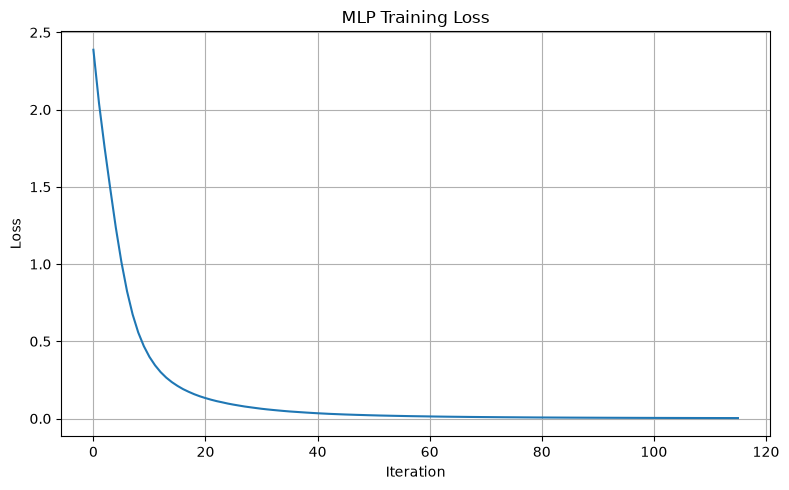

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(
    mlp_model.loss_curve_
)

plt.title("MLP Training Loss")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "images/mlp_training_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 15. Baseline Model Comparison

The Logistic Regression model and the MLP neural network are evaluated
using the same test dataset and the same evaluation metrics.

This allows us to directly compare the performance of the two
approaches.

In [21]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "MLP Neural Network"
    ],
    "Accuracy": [
        logistic_accuracy,
        mlp_accuracy
    ],
    "Precision": [
        logistic_precision,
        mlp_precision
    ],
    "Recall": [
        logistic_recall,
        mlp_recall
    ],
    "F1-Score": [
        logistic_f1,
        mlp_f1
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.972222,0.972126,0.971905,0.971940
1,MLP Neural Network,0.966667,0.967079,0.966504,0.966411


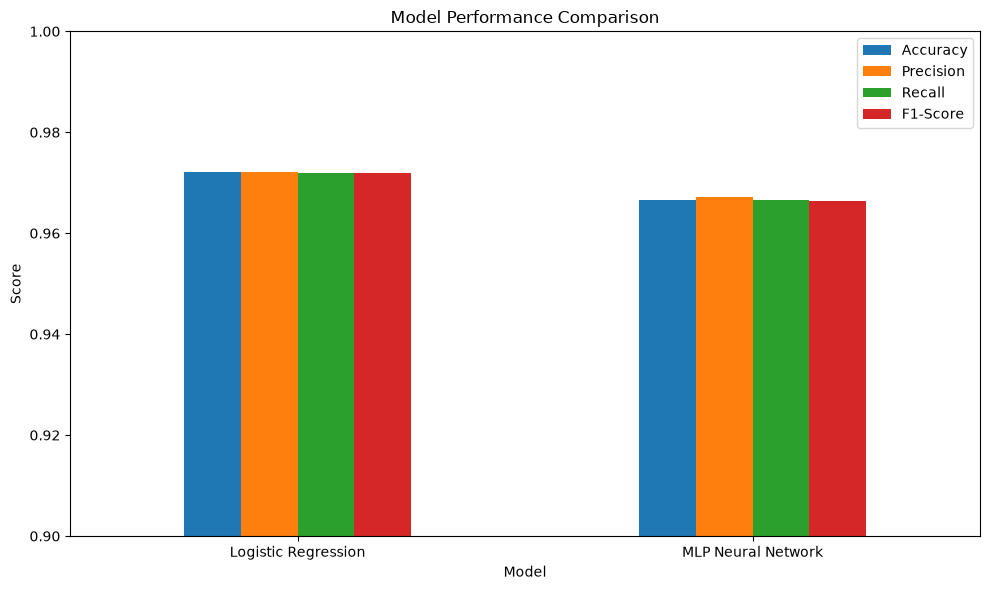

In [22]:
comparison_plot = comparison.set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0.90, 1.00)
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "images/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 16. Neural Network Hyperparameter Tuning

The initial MLP configuration did not outperform the Logistic Regression
baseline.

Instead of assuming that a larger or more complex neural network will
perform better, we will systematically evaluate several configurations.

The hyperparameters considered include:

- Hidden layer architecture
- L2 regularization strength (`alpha`)
- Learning rate initialization

GridSearchCV will evaluate the combinations using 5-fold
cross-validation on the training dataset.

The test set will remain untouched during hyperparameter tuning and
will only be used for the final evaluation.

In [23]:
mlp_pipeline_tuning = Pipeline([
    ("scaler", StandardScaler()),
    (
        "model",
        MLPClassifier(
            activation="relu",
            solver="adam",
            max_iter=300,
            random_state=42
        )
    )
])

param_grid = {
    "model__hidden_layer_sizes": [
        (32,),
        (64,),
        (64, 32),
        (128, 64)
    ],
    "model__alpha": [
        0.0001,
        0.001,
        0.01
    ],
    "model__learning_rate_init": [
        0.001,
        0.01
    ]
}

In [24]:
grid_search = GridSearchCV(
    estimator=mlp_pipeline_tuning,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    return_train_score=True
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(grid_search.best_score_)

Best Parameters:
{'model__alpha': 0.001, 'model__hidden_layer_sizes': (64,), 'model__learning_rate_init': 0.01}

Best Cross-Validation Accuracy:
0.979123112659698


### Best Neural Network Configuration

The grid search identifies the neural network configuration that
achieves the highest mean cross-validation accuracy on the training
data.

The held-out test set has not been used during this process, allowing
us to obtain an unbiased final evaluation after model selection.

In [25]:
best_mlp = grid_search.best_estimator_

best_mlp_predictions = best_mlp.predict(X_test)

best_mlp_accuracy = accuracy_score(
    y_test,
    best_mlp_predictions
)

best_mlp_precision = precision_score(
    y_test,
    best_mlp_predictions,
    average="macro"
)

best_mlp_recall = recall_score(
    y_test,
    best_mlp_predictions,
    average="macro"
)

best_mlp_f1 = f1_score(
    y_test,
    best_mlp_predictions,
    average="macro"
)

print("Final Tuned MLP Performance")
print("-" * 35)
print(f"Accuracy : {best_mlp_accuracy:.4f}")
print(f"Precision: {best_mlp_precision:.4f}")
print(f"Recall   : {best_mlp_recall:.4f}")
print(f"F1-Score : {best_mlp_f1:.4f}")

Final Tuned MLP Performance
-----------------------------------
Accuracy : 0.9833
Precision: 0.9838
Recall   : 0.9832
F1-Score : 0.9832


## 17. Final Model Comparison

After hyperparameter tuning, the optimized MLP neural network
outperformed the Logistic Regression baseline.

The final comparison uses the same evaluation metrics for both models.

This allows us to determine which model provides the strongest
performance on the unseen test dataset.

In [26]:
final_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Initial MLP",
        "Tuned MLP"
    ],
    "Accuracy": [
        logistic_accuracy,
        mlp_accuracy,
        best_mlp_accuracy
    ],
    "Precision": [
        logistic_precision,
        mlp_precision,
        best_mlp_precision
    ],
    "Recall": [
        logistic_recall,
        mlp_recall,
        best_mlp_recall
    ],
    "F1-Score": [
        logistic_f1,
        mlp_f1,
        best_mlp_f1
    ]
})

final_comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.972222,0.972126,0.971905,0.971940
1,Initial MLP,0.966667,0.967079,0.966504,0.966411
2,Tuned MLP,0.983333,0.983780,0.983170,0.983153


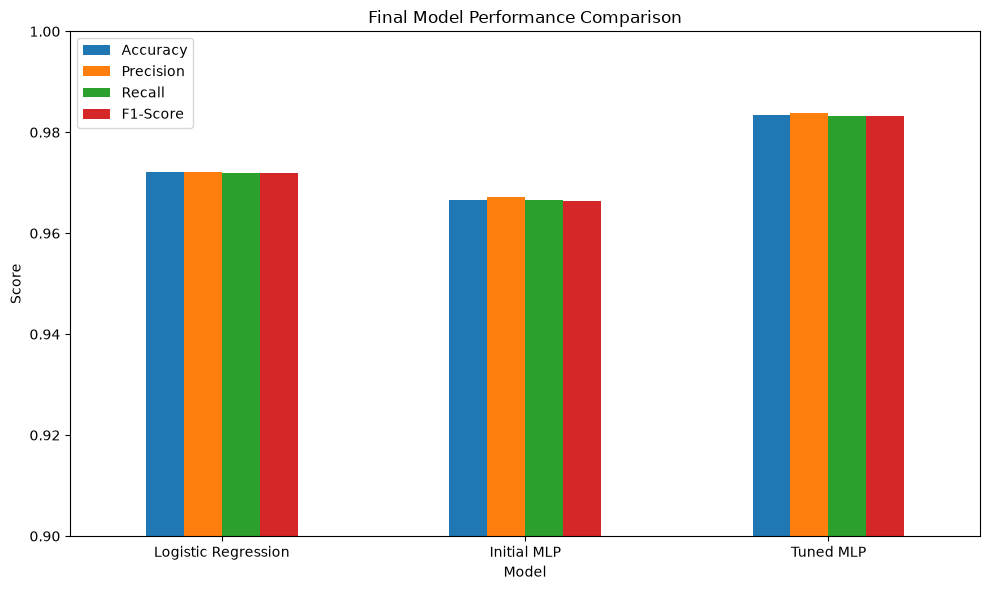

In [27]:
final_comparison_plot = final_comparison.set_index("Model")

final_comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Final Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0.90, 1.00)
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "images/final_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 18. Final Model Selection

The tuned MLP neural network achieved the highest performance among
the evaluated models.

It improved upon both the Logistic Regression baseline and the
initial MLP configuration.

Therefore, the tuned MLP is selected as the final model for detailed
evaluation.

In [28]:
final_model = best_mlp

final_predictions = best_mlp_predictions

print("Final Model: Tuned MLP Neural Network")
print(f"Test Accuracy: {best_mlp_accuracy:.4f}")

Final Model: Tuned MLP Neural Network
Test Accuracy: 0.9833


## 19. Classification Report

The classification report provides precision, recall, and F1-score
for each individual digit class.

This helps identify whether the model performs consistently across
digits 0 through 9.

In [29]:
print("Classification Report")
print("=" * 60)

print(
    classification_report(
        y_test,
        final_predictions
    )
)

Classification Report
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.95      0.97      0.96        36
           2       0.97      1.00      0.99        35
           3       0.97      1.00      0.99        37
           4       0.97      1.00      0.99        36
           5       1.00      0.97      0.99        37
           6       1.00      1.00      1.00        36
           7       1.00      1.00      1.00        36
           8       1.00      0.91      0.96        35
           9       0.97      1.00      0.99        36

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



## 20. Confusion Matrix

A confusion matrix shows how the final model classified each digit.

The rows represent the actual digit labels, while the columns
represent the predicted labels.

Correct predictions appear along the diagonal.

Off-diagonal values represent misclassified images.

<Figure size 900x700 with 0 Axes>

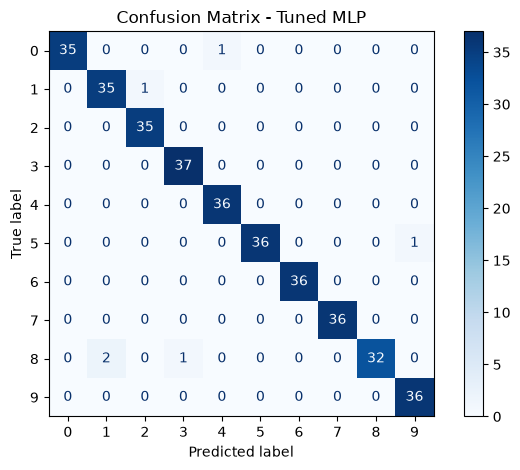

In [30]:
cm = confusion_matrix(
    y_test,
    final_predictions
)

plt.figure(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix - Tuned MLP")

plt.tight_layout()

plt.savefig(
    "images/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 21. Misclassified Images

Even a highly accurate model can make incorrect predictions.

We identify the misclassified test images and visualize several
examples.

This helps us understand which handwritten digits are difficult
for the model to distinguish.

In [31]:
misclassified_indices = np.where(
    final_predictions != y_test
)[0]

print(
    "Number of misclassified images:",
    len(misclassified_indices)
)

print(
    "Test set size:",
    len(y_test)
)

print(
    "Misclassification rate:",
    len(misclassified_indices) / len(y_test)
)

Number of misclassified images: 6
Test set size: 360
Misclassification rate: 0.016666666666666666


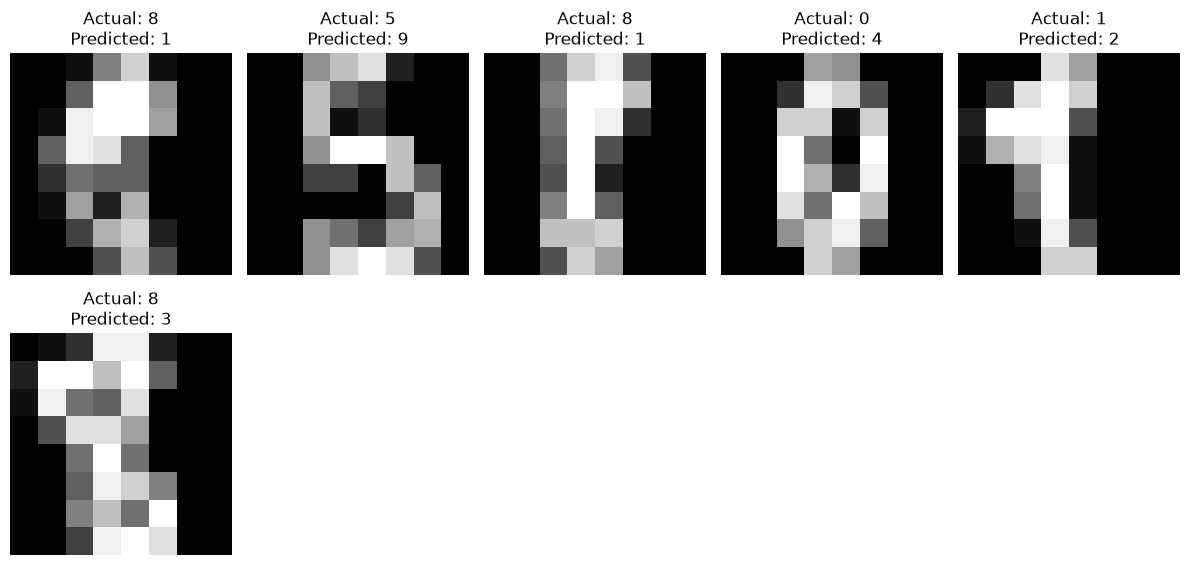

In [32]:
num_images = min(10, len(misclassified_indices))

plt.figure(figsize=(12, 6))

for i in range(num_images):
    index = misclassified_indices[i]

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        digits.images[
            np.where(
                np.all(X == X_test[index], axis=1)
            )[0][0]
        ],
        cmap="gray"
    )

    plt.title(
        f"Actual: {y_test[index]}\n"
        f"Predicted: {final_predictions[index]}"
    )

    plt.axis("off")

plt.tight_layout()

plt.savefig(
    "images/misclassified_digits.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 22. Individual Predictions

The final model can be used to predict individual handwritten digit
images from the test dataset.

The examples below compare the actual digit with the model's prediction.

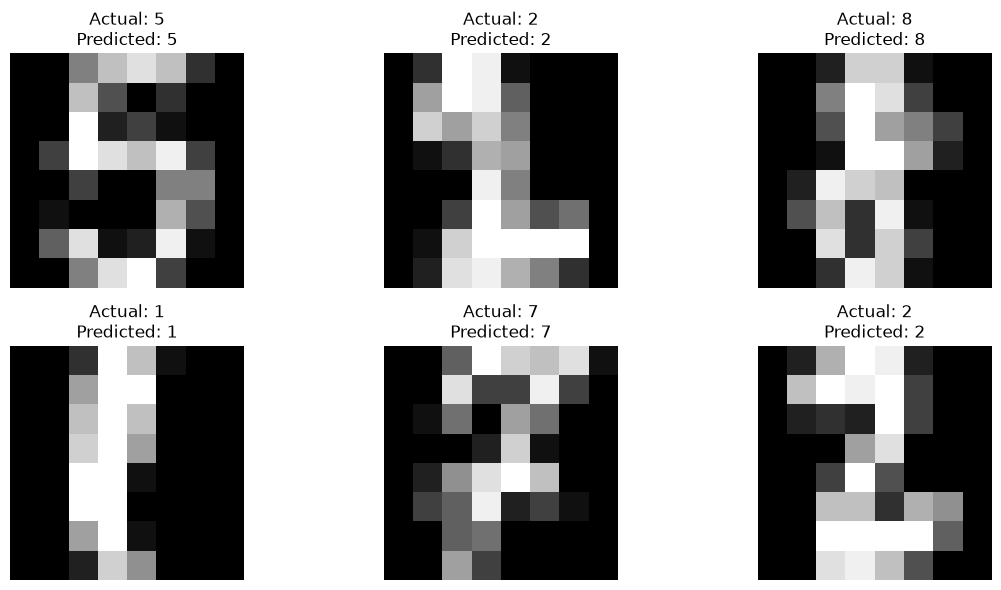

In [33]:
sample_indices = [0, 1, 2, 3, 4, 5]

plt.figure(figsize=(12, 6))

for i, index in enumerate(sample_indices):

    plt.subplot(2, 3, i + 1)

    # Find the corresponding original image
    original_index = np.where(
        np.all(X == X_test[index], axis=1)
    )[0][0]

    plt.imshow(
        digits.images[original_index],
        cmap="gray"
    )

    plt.title(
        f"Actual: {y_test[index]}\n"
        f"Predicted: {final_predictions[index]}"
    )

    plt.axis("off")

plt.tight_layout()

plt.savefig(
    "images/prediction_examples.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 23. Misclassification Analysis

The final tuned MLP achieved an accuracy of 98.33% on the test dataset.

Out of 360 test images, only 6 were incorrectly classified.

The classification report shows that most digit classes achieved
precision, recall, and F1-scores close to 1.00.

Digit 8 had the lowest recall at 0.91, indicating that it was the
most difficult class for the model to recognize correctly.

This is expected because handwritten versions of some digits can have
similar visual patterns.

In [34]:
misclassified_pairs = pd.DataFrame({
    "Actual": y_test[final_predictions != y_test],
    "Predicted": final_predictions[final_predictions != y_test]
})

print("Misclassified Digit Pairs")
print("-" * 30)

print(
    misclassified_pairs
    .value_counts()
    .reset_index(name="Count")
)

Misclassified Digit Pairs
------------------------------
   Actual  Predicted  Count
0       8          1      2
1       5          9      1
2       0          4      1
3       1          2      1
4       8          3      1


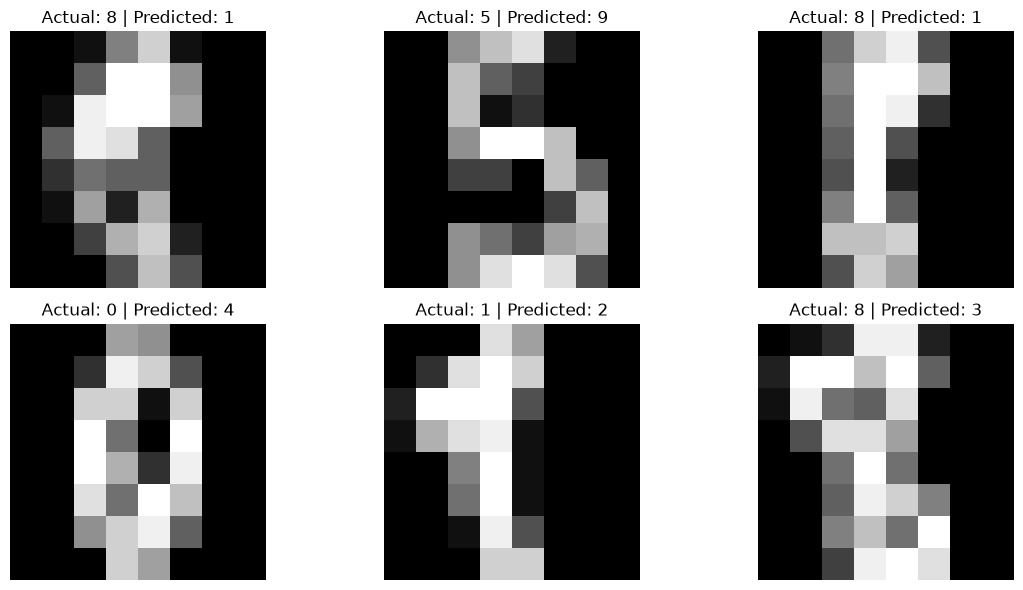

In [35]:
misclassified_indices = np.where(
    final_predictions != y_test
)[0]

num_images = len(misclassified_indices)

plt.figure(figsize=(12, 6))

for i, index in enumerate(misclassified_indices):

    original_index = np.where(
        np.all(X == X_test[index], axis=1)
    )[0][0]

    plt.subplot(2, 3, i + 1)

    plt.imshow(
        digits.images[original_index],
        cmap="gray"
    )

    plt.title(
        f"Actual: {y_test[index]} | "
        f"Predicted: {final_predictions[index]}"
    )

    plt.axis("off")

plt.tight_layout()

plt.savefig(
    "images/misclassified_digits.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 24. Final Model Summary

The tuned MLP neural network was selected as the final model because
it achieved the strongest performance among the evaluated models.

### Final Configuration

- Architecture: 64 input features → 64 hidden neurons → 10 output classes
- Activation: ReLU
- Solver: Adam
- Learning rate: 0.01
- L2 regularization (`alpha`): 0.001
- Cross-validation folds: 5

### Test Performance

- Accuracy: 98.33%
- Precision: 98.38%
- Recall: 98.32%
- F1-Score: 98.32%

The model correctly classified 354 out of 360 test images and
misclassified only 6 images.

## 25. Conclusion

This project demonstrated an end-to-end machine learning workflow
for handwritten digit recognition.

The project began with a Logistic Regression baseline, which achieved
97.22% test accuracy.

An initial Multi-Layer Perceptron neural network was then evaluated,
achieving 96.67% accuracy.

Hyperparameter tuning was performed using GridSearchCV with 5-fold
cross-validation. The optimized MLP achieved a cross-validation
accuracy of 97.91%.

On the unseen test set, the tuned MLP achieved:

- 98.33% accuracy
- 98.38% macro precision
- 98.32% macro recall
- 98.32% macro F1-score

Only 6 out of 360 test images were misclassified.

The results demonstrate that the optimized neural network was able
to learn effective representations for the small 8 × 8 handwritten
digit images.

This project also demonstrates important machine learning practices,
including:

- Exploratory data analysis
- Image visualization
- Stratified train/test splitting
- Feature standardization
- Pipeline-based preprocessing
- Baseline model development
- Neural network classification
- Cross-validation
- Hyperparameter tuning
- Confusion matrix analysis
- Misclassification analysis
- Final model selection

## 26. Individual Prediction Examples

The final model can be used to classify individual handwritten digit
images from the unseen test set.

The examples below compare the actual digit with the prediction made
by the trained neural network.

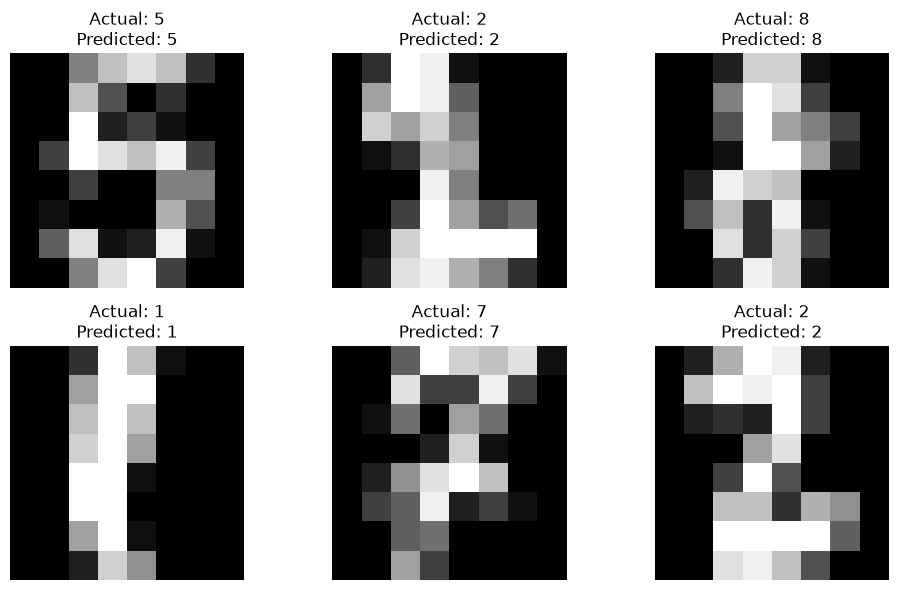

In [36]:
sample_indices = [0, 1, 2, 3, 4, 5]

plt.figure(figsize=(10, 6))

for i, index in enumerate(sample_indices):

    original_index = np.where(
        np.all(X == X_test[index], axis=1)
    )[0][0]

    plt.subplot(2, 3, i + 1)

    plt.imshow(
        digits.images[original_index],
        cmap="gray"
    )

    plt.title(
        f"Actual: {y_test[index]}\n"
        f"Predicted: {final_predictions[index]}"
    )

    plt.axis("off")

plt.tight_layout()

plt.savefig(
    "images/prediction_examples.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [37]:
final_comparison.to_csv(
    "images/final_model_results.csv",
    index=False
)

print("Final model results saved successfully.")

Final model results saved successfully.


In [38]:
print("Final Model Performance")
print("=" * 40)

print(f"Accuracy : {best_mlp_accuracy:.4f}")
print(f"Precision: {best_mlp_precision:.4f}")
print(f"Recall   : {best_mlp_recall:.4f}")
print(f"F1-Score : {best_mlp_f1:.4f}")

print("\nMisclassified Images:", len(misclassified_indices))
print("Test Images:", len(y_test))

Final Model Performance
Accuracy : 0.9833
Precision: 0.9838
Recall   : 0.9832
F1-Score : 0.9832

Misclassified Images: 6
Test Images: 360
